# LGBTQ+ Tweet Categorization - Zero-Shot Multi-Label Scoring


## Overview

This notebook classifies LGBTQ+-labeled corporate tweets into four meaningful categories defined by the research team:

| Category | Description | Example |
|----------|-------------|--------|
| **Support** | General expressions of solidarity, inclusivity, or celebration | "We're proud to celebrate Pride Month with our LGBTQ+ community" |
| **Company Action** | Specific policies, programs, donations, or initiatives taken by the company | "We've launched a new benefits package covering same-sex partners" |
| **Employee / Executive Profile** | Spotlights on individual employees or executives discussing pride or identity | "Meet Maria, an openly gay engineer who leads our DEI council" |
| **Political Statement** | References to legislation, rights, or political positions | "We oppose legislation that discriminates against LGBTQ+ individuals" |

### Why Zero-Shot Classification?

Topic modeling (like LDA) finds themes automatically but doesn't know which categories we want in advance, we'd have to guess what the output means. Zero-shot classification works the other way: we tell it our four categories and it scores each tweet against them directly. This is better suited to this task because the categories are already defined by the research goals.

The model used is `facebook/bart-large-mnli` — a pre-trained model that understands natural language and does not require any training data from our dataset.

### Multi-Label Scoring

A tweet is not always about only one thing — a company can announce a new benefits policy (**Company Action**) while also expressing solidarity (**Support**) in the same post. Rather than forcing every tweet into a single exclusive category, this notebook keeps an **independent score for each of the four categories** for every tweet. Support and Company Action, for example, are allowed to both score high on the same tweet. The highest-scoring category is still tracked as a convenience label, but it is no longer the primary output — the four continuous scores are.


---
## Section 1 — Setup


### 1.1 — Install & Import Libraries


In [1]:
# ── Install Hugging Face transformers (includes zero-shot pipeline) ───────────
!pip install transformers torch --quiet

In [2]:
# ── Core libraries ───────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display
import warnings
import time
import os
warnings.filterwarnings('ignore')

# ── Hugging Face zero-shot pipeline ─────────────────────────────────────────
from transformers import pipeline

# ── Plot styling (matches main notebook) ────────────────────────────────────
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.15)
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
    'figure.titlesize': 16,
    'figure.titleweight': 'bold',
})

# ── Colors ───────────────────────────────────────────────────────────────────
LGBTQ_COLOR     = '#8B5CF6'   # purple
NON_LGBTQ_COLOR = '#64748B'   # slate gray
ACCENT_COLOR    = '#F59E0B'   # amber

# One color per category
CAT_COLORS = {
    'Support'             : '#22C55E',   # green
    'Company Action'      : '#3B82F6',   # blue
    'Employee Profile'    : '#F59E0B',   # amber
    'Political Statement' : '#EF4444',   # red
}

print('✅ Libraries imported successfully.')

✅ Libraries imported successfully.


### 1.2 — Load Dataset


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
FILE_PATH = '/content/drive/MyDrive/Colab Notebooks/Tweets.csv'

df = pd.read_csv(FILE_PATH, low_memory=False, on_bad_lines='skip')
# ── Parse dates ──────────────────────────────────────────────────────────────
df['createdAt'] = pd.to_datetime(df['createdAt'], utc=True, errors='coerce')
df['year']      = df['createdAt'].dt.year
df['month']     = df['createdAt'].dt.month

print(f'✅ Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'   LGBTQ+ tweets : {(df["binary"] == 1).sum():,}')

✅ Dataset loaded: 1,585,500 rows × 19 columns
   LGBTQ+ tweets : 52,791


### 1.3 — Filter to LGBTQ+ Tweets

Classification only runs on the LGBTQ+-labeled subset. This keeps it focused and manageable.

In [5]:
# ── Isolate LGBTQ+ tweets ────────────────────────────────────────────────────
df_lgbtq = df[df['binary'] == 1].copy().reset_index(drop=True)

# Clean text — remove nulls
df_lgbtq['text'] = df_lgbtq['text'].fillna('').astype(str)

print(f'✅ LGBTQ+ subset: {len(df_lgbtq):,} tweets')
print(f'   Companies : {df_lgbtq["author_userName"].nunique():,}')
print(f'   Date range: {df_lgbtq["createdAt"].min().date()}  →  {df_lgbtq["createdAt"].max().date()}')

✅ LGBTQ+ subset: 52,791 tweets
   Companies : 390
   Date range: 2018-01-01  →  2024-07-14


---
## Section 2 — Define Categories & Load Model


### 2.1 — Category Definitions

The labels below are what the model scores each tweet against. The wording matters — clear, descriptive labels produce better results than single words.

In [6]:
# ── Four research categories ──────────────────────────────────────────────────
# These are passed directly to the zero-shot classifier as candidate labels.
# Changes to wording can be done here if needed
CANDIDATE_LABELS = [
    'support and celebration of LGBTQ+ community and Pride',
    'specific company action, policy, program, or initiative for LGBTQ+ inclusion',
    'employee or executive profile or personal story about LGBTQ+ identity',
    'political statement or position on LGBTQ+ legislation or rights',
]

# Shorter display names mapped to those labels (used in charts and tables)
LABEL_MAP = {
    'support and celebration of LGBTQ+ community and Pride'                         : 'Support',
    'specific company action, policy, program, or initiative for LGBTQ+ inclusion'  : 'Company Action',
    'employee or executive profile or personal story about LGBTQ+ identity'          : 'Employee Profile',
    'political statement or position on LGBTQ+ legislation or rights'                : 'Political Statement',
}

# ── Multi-label scoring ──────────────────────────────────────────────────────
# Every tweet gets an INDEPENDENT score for each of the four categories below
# (not one exclusive label). Support and Company Action, for example, can both
# score high on the same tweet.
cat_order = ['Support', 'Company Action', 'Employee Profile', 'Political Statement']

# Display category name -> output dataframe column name
SCORE_COL_MAP = {
    'Support'             : 'support_score',
    'Company Action'      : 'company_action_score',
    'Employee Profile'    : 'employee_profile_score',
    'Political Statement' : 'political_score',
}

print('Categories defined:')
for short, full in zip(LABEL_MAP.values(), LABEL_MAP.keys()):
    print(f'  [{short}]  →  "{full}"  →  column "{SCORE_COL_MAP[short]}"')

Categories defined:
  [Support]  →  "support and celebration of LGBTQ+ community and Pride"  →  column "support_score"
  [Company Action]  →  "specific company action, policy, program, or initiative for LGBTQ+ inclusion"  →  column "company_action_score"
  [Employee Profile]  →  "employee or executive profile or personal story about LGBTQ+ identity"  →  column "employee_profile_score"
  [Political Statement]  →  "political statement or position on LGBTQ+ legislation or rights"  →  column "political_score"


### 2.2 — Load Zero-Shot Classifier

This downloads the `facebook/bart-large-mnli` model

In [7]:
# ── Load the zero-shot classification pipeline ───────────────────────────────
# device=0 uses the GPU (much faster); device=-1 uses CPU (slower but works)
print('Loading model... (downloads ~1.6 GB on first run, then cached)')

classifier = pipeline(
    'zero-shot-classification',
    model='facebook/bart-large-mnli',
    device=0   # GPU — change to -1 if you did not enable GPU runtime
)

print('✅ Model loaded and ready.')

Loading model... (downloads ~1.6 GB on first run, then cached)


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

✅ Model loaded and ready.


### 2.3 — Quick Test on 5 Tweets

Testing the classifier on a small sample before running the full dataset. Because every category gets its own score, we print all four scores per tweet (not just the winning one) — this makes it easy to see cases where a tweet legitimately scores high on more than one category.

In [8]:
# ── Test on 5 sample tweets ──────────────────────────────────────────────────
test_tweets = df_lgbtq['text'].sample(5, random_state=42).tolist()

print('CLASSIFIER TEST — 5 SAMPLE TWEETS')
print('═' * 60)

for tweet in test_tweets:
    result = classifier(tweet[:512], CANDIDATE_LABELS)
    scores_by_cat = {LABEL_MAP[l]: s for l, s in zip(result['labels'], result['scores'])}
    top_label = LABEL_MAP[result['labels'][0]]
    top_score = result['scores'][0]

    print(f'\nTweet   : "{tweet[:120]}"')
    for cat in cat_order:
        marker = '  ←  highest' if cat == top_label else ''
        print(f'  {cat:<20}: {scores_by_cat[cat]:.3f}{marker}')
    print()

print('═' * 60)
print('\n✅ Test complete. Review results above before running full classification.')
print('   If any labels look wrong, adjust the CANDIDATE_LABELS wording in Section 2.1.')

---
## Section 3 — Run Full Classification

This is the main processing step. It runs the classifier on all ~52,000 LGBTQ+ tweets in batches. For every tweet it keeps all four category scores independently, rather than only the winning label.

In [9]:
CHECKPOINT_PATH = '/content/drive/MyDrive/lgbtq_classified_checkpoint.csv'
BATCH_SIZE      = 32    # tweets per batch — GPU handles this comfortably
SAVE_EVERY      = 1000  # save checkpoint every N tweets

# ── Resume from checkpoint if one exists ────────────────────────────────────
if os.path.exists(CHECKPOINT_PATH):
    df_done = pd.read_csv(CHECKPOINT_PATH)
    done_indices = set(df_done['original_index'].tolist())
    print(f'✅ Checkpoint found: {len(df_done):,} tweets already classified. Resuming...')
else:
    df_done = pd.DataFrame()
    done_indices = set()
    print('No checkpoint found. Starting from scratch.')

# ── Identify remaining tweets ────────────────────────────────────────────────
remaining = df_lgbtq[~df_lgbtq.index.isin(done_indices)].copy()
print(f'Tweets remaining to classify: {len(remaining):,}')
print(f'Estimated time (GPU): ~{len(remaining)//60//60}h {(len(remaining)//60)%60}m')

# ── Run classification in batches ────────────────────────────────────────────
results = []
texts   = remaining['text'].tolist()
indices = remaining.index.tolist()

start_time = time.time()

for i in range(0, len(texts), BATCH_SIZE):
    batch_texts   = [t[:512] for t in texts[i:i+BATCH_SIZE]]   # truncate to model max
    batch_indices = indices[i:i+BATCH_SIZE]

    batch_results = classifier(batch_texts, CANDIDATE_LABELS, batch_size=BATCH_SIZE)

    for idx, res in zip(batch_indices, batch_results):
        # Independent score for every category — this is the primary output.
        all_scores = {LABEL_MAP[l]: s for l, s in zip(res['labels'], res['scores'])}

        # Highest-scoring category kept only as a secondary, convenience column.
        top_label = LABEL_MAP[res['labels'][0]]
        top_score = res['scores'][0]

        results.append({
            'original_index'        : idx,
            'support_score'         : round(all_scores.get('Support', 0), 4),
            'company_action_score'  : round(all_scores.get('Company Action', 0), 4),
            'employee_profile_score': round(all_scores.get('Employee Profile', 0), 4),
            'political_score'       : round(all_scores.get('Political Statement', 0), 4),
            'highest_category'      : top_label,
            'confidence'            : round(top_score, 4),   # confidence = score of highest_category
        })

    # ── Progress update and checkpoint ───────────────────────────────────────
    processed = len(results)
    if processed % SAVE_EVERY < BATCH_SIZE or i + BATCH_SIZE >= len(texts):
        elapsed  = time.time() - start_time
        rate     = processed / elapsed if elapsed > 0 else 1
        remaining_t = (len(texts) - processed) / rate
        print(f'  [{processed:>6,} / {len(texts):,}]  '
              f'Speed: {rate:.0f} tweets/sec  '
              f'ETA: {remaining_t/60:.0f} min')

        # Save checkpoint
        batch_df = pd.DataFrame(results)
        combined = pd.concat([df_done, batch_df], ignore_index=True) if len(df_done) > 0 else batch_df
        combined.to_csv(CHECKPOINT_PATH, index=False)

print(f'\n✅ Classification complete!')

No checkpoint found. Starting from scratch.
Tweets remaining to classify: 52,791
Estimated time (GPU): ~14h 39m


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


  [ 1,024 / 52,791]  Speed: 12 tweets/sec  ETA: 74 min
  [ 2,016 / 52,791]  Speed: 11 tweets/sec  ETA: 74 min
  [ 3,008 / 52,791]  Speed: 12 tweets/sec  ETA: 69 min
  [ 4,000 / 52,791]  Speed: 12 tweets/sec  ETA: 66 min
  [ 5,024 / 52,791]  Speed: 12 tweets/sec  ETA: 66 min
  [ 6,016 / 52,791]  Speed: 12 tweets/sec  ETA: 64 min
  [ 7,008 / 52,791]  Speed: 12 tweets/sec  ETA: 64 min
  [ 8,000 / 52,791]  Speed: 12 tweets/sec  ETA: 63 min
  [ 9,024 / 52,791]  Speed: 12 tweets/sec  ETA: 62 min
  [10,016 / 52,791]  Speed: 12 tweets/sec  ETA: 61 min
  [11,008 / 52,791]  Speed: 12 tweets/sec  ETA: 59 min
  [12,000 / 52,791]  Speed: 12 tweets/sec  ETA: 58 min
  [13,024 / 52,791]  Speed: 12 tweets/sec  ETA: 57 min
  [14,016 / 52,791]  Speed: 12 tweets/sec  ETA: 56 min
  [15,008 / 52,791]  Speed: 12 tweets/sec  ETA: 55 min
  [16,000 / 52,791]  Speed: 11 tweets/sec  ETA: 54 min
  [17,024 / 52,791]  Speed: 11 tweets/sec  ETA: 52 min
  [18,016 / 52,791]  Speed: 11 tweets/sec  ETA: 51 min
  [19,008 

In [10]:
# ── Merge classification results back onto the LGBTQ+ dataframe ─────────────
classified = pd.read_csv(CHECKPOINT_PATH)
classified = classified.set_index('original_index')

df_lgbtq = df_lgbtq.join(classified, how='left')

# ── Save final merged file ───────────────────────────────────────────────────
# Final dataframe contains: original tweet info + the four independent scores
# + highest_category (kept only as a convenience column, not the primary output).
df_lgbtq.to_csv('/content/drive/MyDrive/lgbtq_tweets_classified.csv', index=False)

score_cols = list(SCORE_COL_MAP.values())
print(f'✅ Results merged. Classified: {df_lgbtq[score_cols].notna().all(axis=1).sum():,} tweets')
print(f'   Saved to: lgbtq_tweets_classified.csv')
print(f'\nAverage score per category:')
print(df_lgbtq[score_cols].mean().round(3).to_string())
print(f'\nHighest-scoring category distribution (secondary, informational only):')
print(df_lgbtq['highest_category'].value_counts().to_string())

✅ Results merged. Classified: 52,791 tweets
   Saved to: lgbtq_tweets_classified.csv

Average score per category:
support_score             0.183
company_action_score      0.236
employee_profile_score    0.407
political_score           0.174

Highest-scoring category distribution (secondary, informational only):
highest_category
Employee Profile       37018
Company Action          7969
Support                 5471
Political Statement     2333


---
## Section 4 — Category Score Distributions

Since every tweet now carries four independent scores instead of one exclusive label, we look at the distribution of each score separately across all LGBTQ+ tweets.

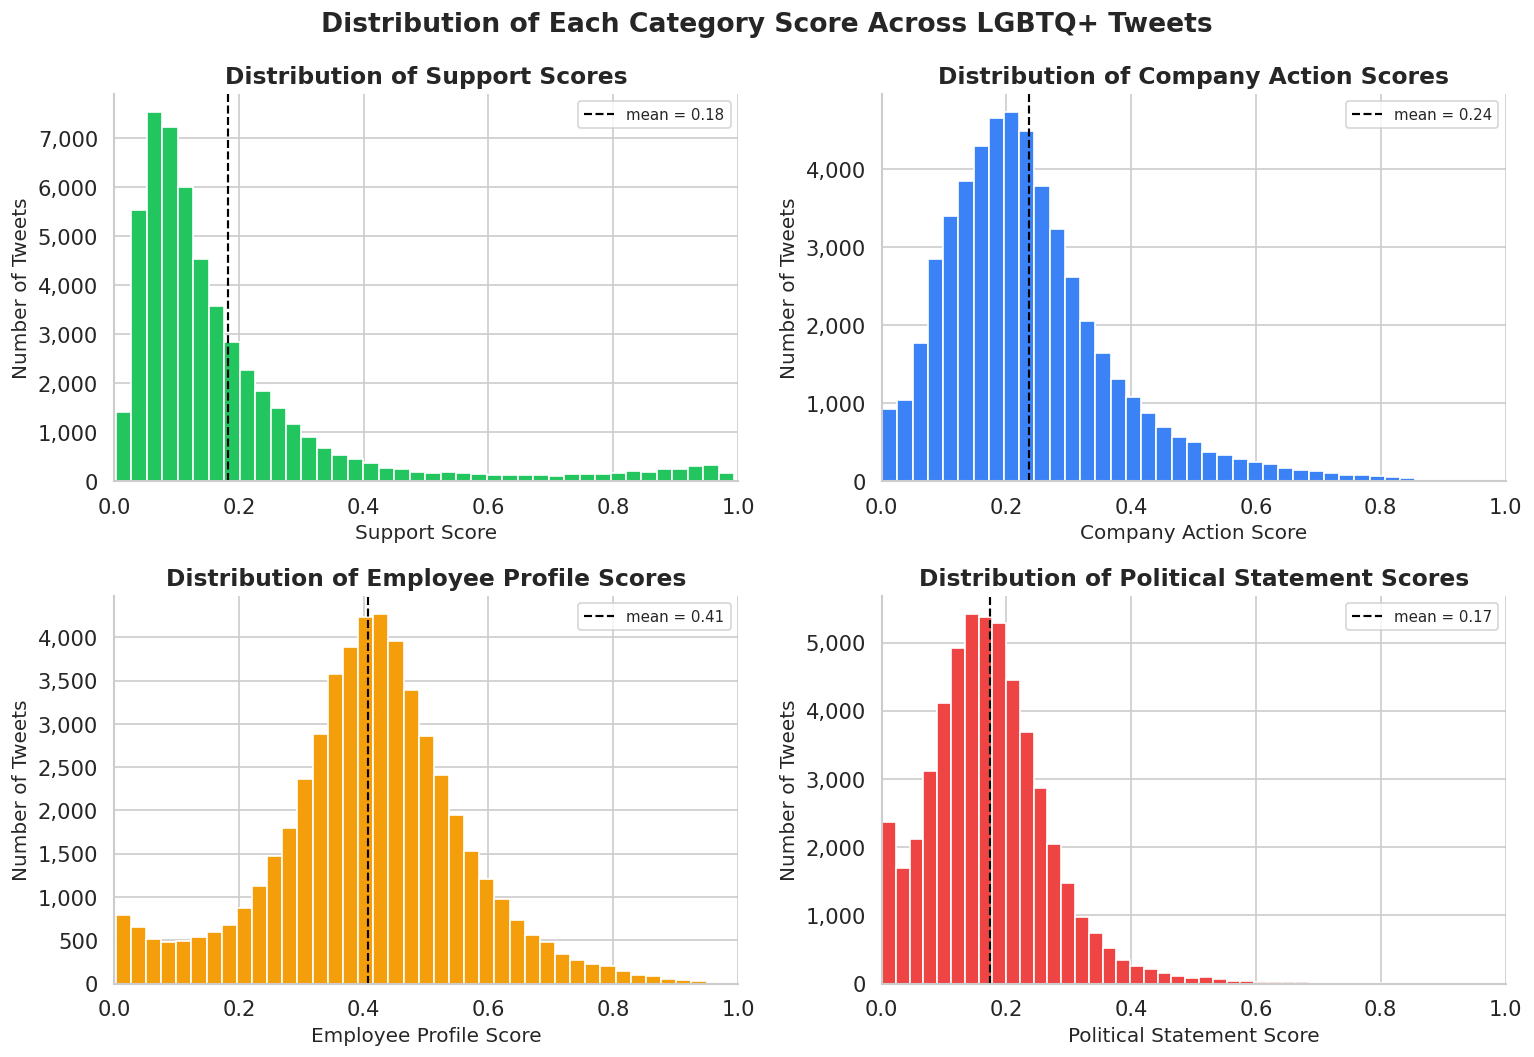

,mean,std,min,max
Support,0.183,0.189,0.003,0.994
Company Action,0.236,0.136,0.001,0.977
Employee Profile,0.407,0.154,0.003,0.974
Political Statement,0.174,0.097,0.001,0.884


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for ax, cat in zip(axes, cat_order):
    col = SCORE_COL_MAP[cat]
    ax.hist(df_lgbtq[col].dropna(), bins=40, color=CAT_COLORS[cat], edgecolor='white')
    ax.axvline(df_lgbtq[col].mean(), color='black', linestyle='--', linewidth=1.3,
               label=f'mean = {df_lgbtq[col].mean():.2f}')
    ax.set_title(f'Distribution of {cat} Scores')
    ax.set_xlabel(f'{cat} Score')
    ax.set_ylabel('Number of Tweets')
    ax.set_xlim(0, 1)
    ax.legend(fontsize=9)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
    sns.despine(ax=ax)

fig.suptitle('Distribution of Each Category Score Across LGBTQ+ Tweets')
plt.tight_layout()
plt.savefig('fig_score_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Summary table ────────────────────────────────────────────────────────────
score_summary = df_lgbtq[[SCORE_COL_MAP[c] for c in cat_order]].describe().T
score_summary.index = cat_order
display(score_summary[['mean', 'std', 'min', 'max']].style.format('{:.3f}'))

---
## Section 5 — Category Trends Over Time

Has the mix of categories shifted from 2018 to 2023? Rather than category counts, we track the **average score per category by year** — this reveals whether corporate LGBTQ+ communication has become more or less action-oriented or politically engaged over time, without forcing each tweet into a single bucket.

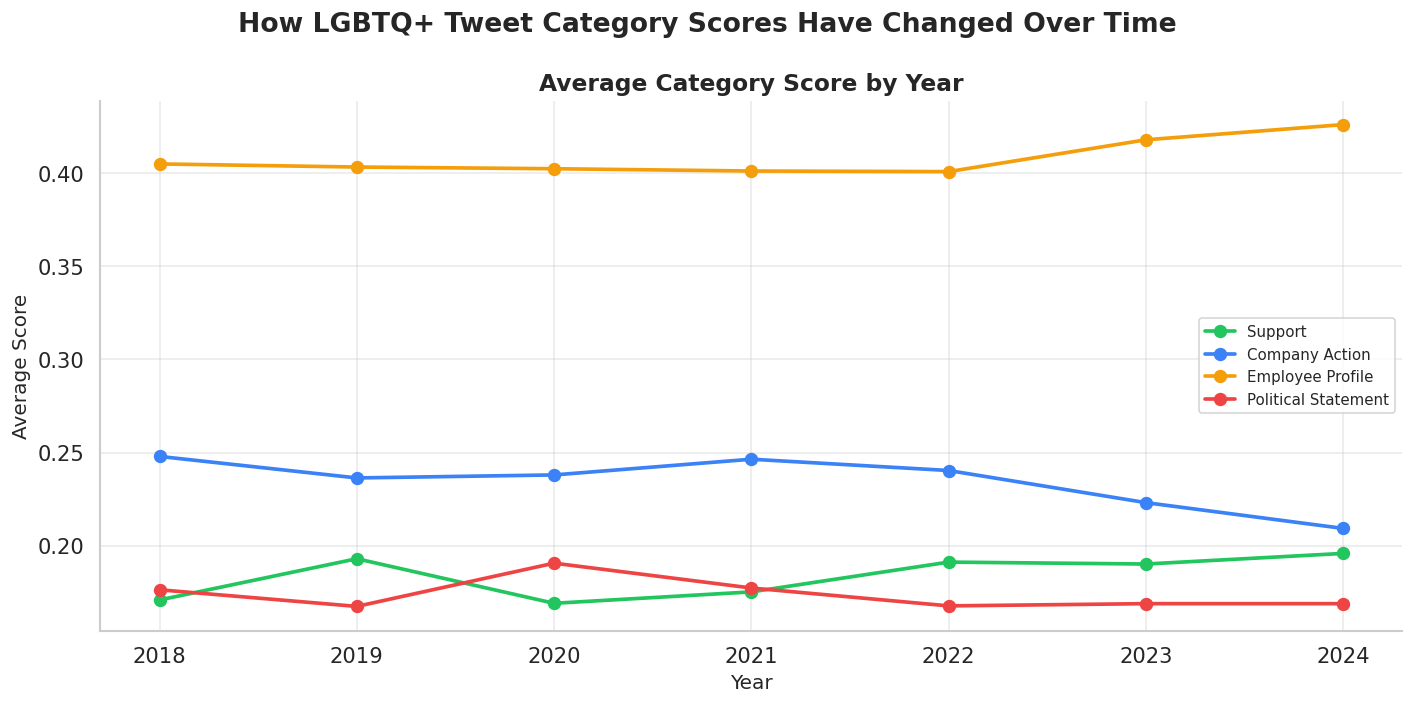

,Support,Company Action,Employee Profile,Political Statement
year,,,,
2018,0.171,0.248,0.405,0.176
2019,0.193,0.236,0.403,0.167
2020,0.169,0.238,0.402,0.191
2021,0.175,0.246,0.401,0.177
2022,0.191,0.240,0.401,0.168
2023,0.190,0.223,0.418,0.169
2024,0.196,0.209,0.426,0.169


In [12]:
# ── Average score per category, by year ─────────────────────────────────────
yearly_scores = df_lgbtq.groupby('year')[[SCORE_COL_MAP[c] for c in cat_order]].mean()
yearly_scores.columns = cat_order

fig, ax = plt.subplots(figsize=(12, 6))

for cat in cat_order:
    ax.plot(
        yearly_scores.index,
        yearly_scores[cat],
        marker='o', linewidth=2.2,
        color=CAT_COLORS[cat],
        label=cat, markersize=7
    )

ax.set_title('Average Category Score by Year')
ax.set_xlabel('Year')
ax.set_ylabel('Average Score')
ax.set_xticks(yearly_scores.index)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.4)
sns.despine(ax=ax)

fig.suptitle('How LGBTQ+ Tweet Category Scores Have Changed Over Time')
plt.tight_layout()
plt.savefig('fig_score_yearly_trend.png', dpi=150, bbox_inches='tight')
plt.show()

display(yearly_scores.round(3))

---
## Section 6 — Category Score by Month (Seasonality)

Same idea as the yearly trend, but averaged by calendar month across all years — useful for spotting seasonal effects like Pride Month (June).

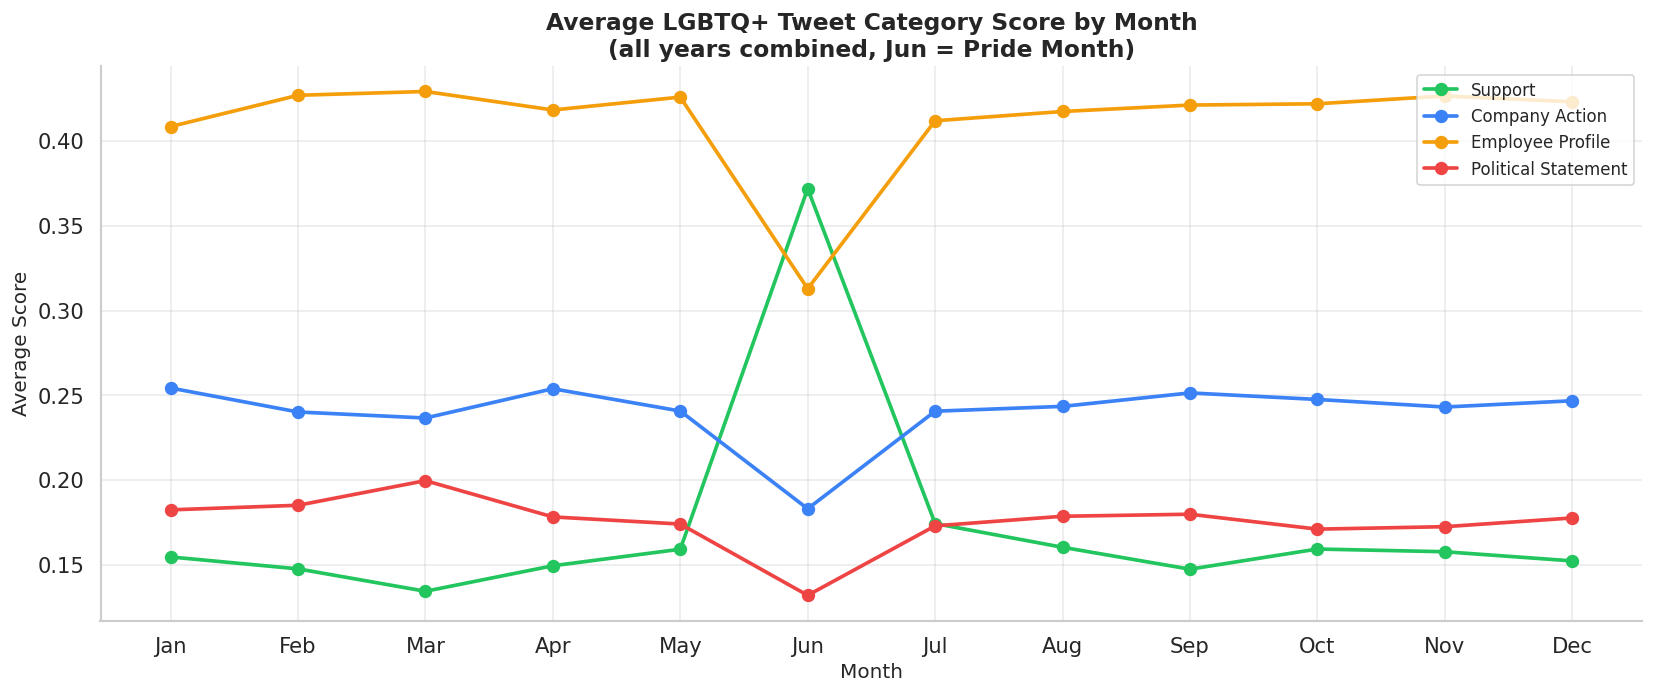

In [13]:
month_names = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']

monthly_scores = df_lgbtq.groupby('month')[[SCORE_COL_MAP[c] for c in cat_order]].mean()
monthly_scores.columns = cat_order
monthly_scores.index = [month_names[m-1] for m in monthly_scores.index]

fig, ax = plt.subplots(figsize=(14, 6))

for cat in cat_order:
    ax.plot(
        monthly_scores.index,
        monthly_scores[cat],
        marker='o', linewidth=2.2,
        color=CAT_COLORS[cat],
        label=cat, markersize=7
    )

ax.set_title('Average LGBTQ+ Tweet Category Score by Month\n(all years combined, Jun = Pride Month)')
ax.set_xlabel('Month')
ax.set_ylabel('Average Score')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.4)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('fig_score_monthly.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 7 — Category Score by Company

Which companies score highest on which type of LGBTQ+ communication? Instead of assigning each company a single dominant category, we calculate the **average score per category, per company**, and rank companies by each score separately.

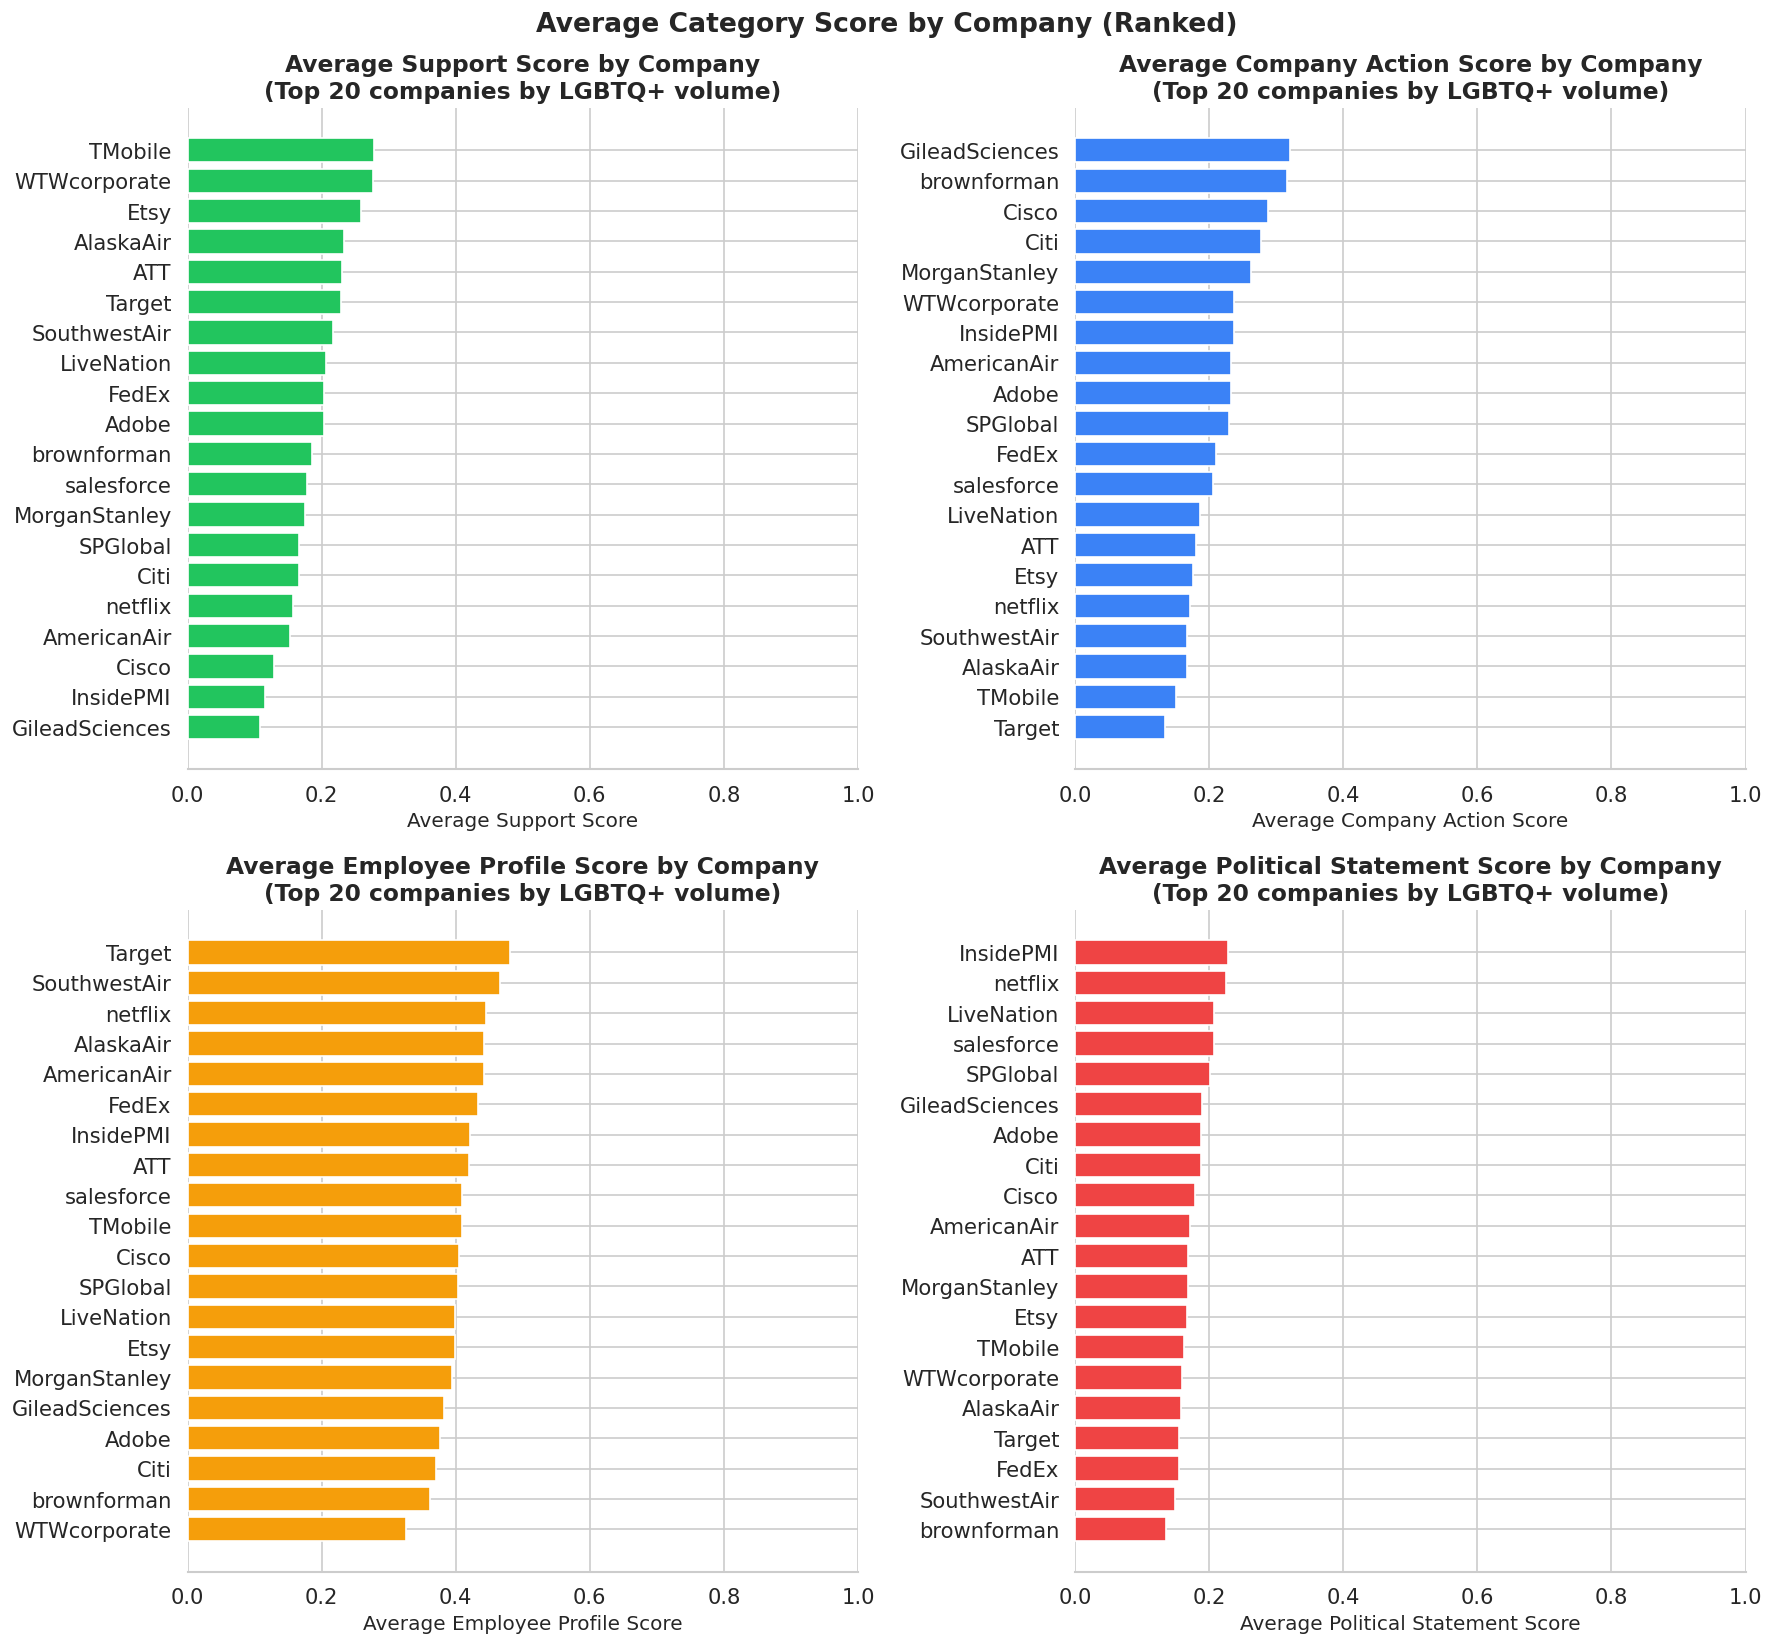

In [14]:
# ── Average score per category for the top 20 companies by LGBTQ+ volume ────
top20_companies = (
    df_lgbtq['author_userName']
    .value_counts()
    .head(20)
    .index.tolist()
)

company_scores = (
    df_lgbtq[df_lgbtq['author_userName'].isin(top20_companies)]
    .groupby('author_userName')[[SCORE_COL_MAP[c] for c in cat_order]]
    .mean()
)
company_scores.columns = cat_order

fig, axes = plt.subplots(2, 2, figsize=(15, 14))
axes = axes.flatten()

for ax, cat in zip(axes, cat_order):
    ranked = company_scores[cat].sort_values(ascending=True)
    ax.barh(ranked.index, ranked.values, color=CAT_COLORS[cat], edgecolor='white')
    ax.set_title(f'Average {cat} Score by Company\n(Top 20 companies by LGBTQ+ volume)')
    ax.set_xlabel(f'Average {cat} Score')
    ax.set_xlim(0, 1)
    sns.despine(ax=ax, left=True)

fig.suptitle('Average Category Score by Company (Ranked)')
plt.tight_layout()
plt.savefig('fig_score_by_company.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 8 — Confidence Score Analysis

The classifier assigns a confidence score to each tweet — the score of its highest-scoring category. Low-confidence tweets are ones where the model was uncertain across all four categories — worth examining to validate the results.

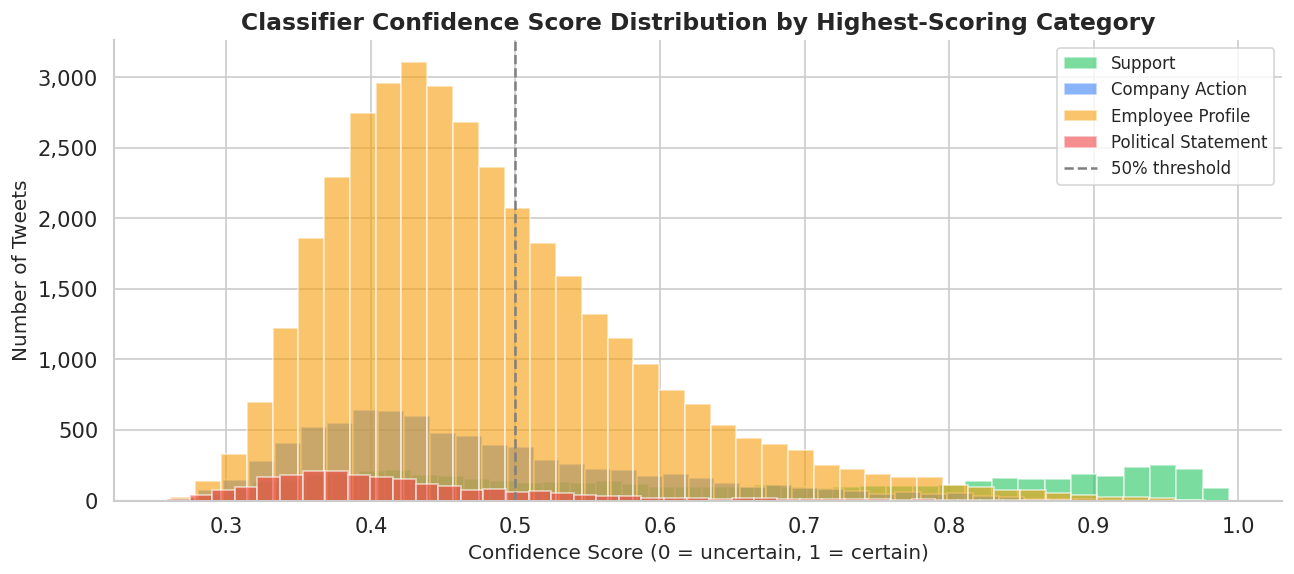

CONFIDENCE SCORES BY HIGHEST-SCORING CATEGORY


,Mean Confidence,Median Confidence,Min Confidence
highest_category,,,
Company Action,0.475,0.445,0.262
Employee Profile,0.479,0.458,0.261
Political Statement,0.427,0.401,0.259
Support,0.648,0.638,0.264


In [15]:
# ── Confidence distribution by highest-scoring category ──────────────────────
fig, ax = plt.subplots(figsize=(11, 5))

for cat in cat_order:
    subset = df_lgbtq[df_lgbtq['highest_category'] == cat]['confidence'].dropna()
    ax.hist(subset, bins=40, alpha=0.6, label=cat,
            color=CAT_COLORS[cat], edgecolor='white')

ax.axvline(0.5, color='gray', linestyle='--', linewidth=1.5, label='50% threshold')
ax.set_title('Classifier Confidence Score Distribution by Highest-Scoring Category')
ax.set_xlabel('Confidence Score (0 = uncertain, 1 = certain)')
ax.set_ylabel('Number of Tweets')
ax.legend(fontsize=10)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
sns.despine()
plt.tight_layout()
plt.savefig('fig_confidence_dist.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Summary stats ─────────────────────────────────────────────────────────────
conf_stats = df_lgbtq.groupby('highest_category')['confidence'].agg(['mean','median','min']).round(3)
conf_stats.columns = ['Mean Confidence', 'Median Confidence', 'Min Confidence']
print('CONFIDENCE SCORES BY HIGHEST-SCORING CATEGORY')
display(conf_stats.style.format('{:.3f}').background_gradient(cmap='Greens'))

---
## Section 9 — High-Scoring Tweets per Category

Reviewing examples confirms the classifier is working correctly. Because scores are independent, the top tweets for each category are pulled directly from that category's own score column — a tweet can appear in more than one category's list if it scores high on both.

In [16]:
# ── Top 5 highest-scoring examples for EACH category (independently) ─────────
for cat in cat_order:
    score_col = SCORE_COL_MAP[cat]
    subset = (
        df_lgbtq
        .nlargest(5, score_col)
        [['author_userName', 'text', score_col]]
        .reset_index(drop=True)
    )
    print(f'\n{"═"*65}')
    print(f'  TOP {cat.upper()} TWEETS  (top 5 by {score_col})')
    print(f'{"═"*65}')
    for _, row in subset.iterrows():
        print(f'  [{row["author_userName"]}]  {score_col}={row[score_col]:.3f}')
        print(f'  "{row["text"][:160]}"')
        print()

---
## Section 10 — Low Confidence Review

Tweets where the classifier was unsure (confidence < 0.40) are worth a quick manual review to spot any systematic errors.

In [17]:
LOW_CONF_THRESHOLD = 0.40

low_conf = df_lgbtq[df_lgbtq['confidence'] < LOW_CONF_THRESHOLD].copy()

print(f'Tweets below {LOW_CONF_THRESHOLD} confidence: {len(low_conf):,}  '
      f'({len(low_conf)/len(df_lgbtq)*100:.1f}% of total)')

print('\nLow-confidence breakdown by highest-scoring category:')
display(low_conf['highest_category'].value_counts().to_frame())

print('\nSample low-confidence tweets:')
sample_low = low_conf.sample(min(10, len(low_conf)), random_state=42)
for _, row in sample_low.iterrows():
    print(f'  [{row["author_userName"]}]  highest_category={row["highest_category"]}  conf={row["confidence"]:.3f}')
    print(f'  "{row["text"][:150]}"')
    print()

Tweets below 0.4 confidence: 13,235  (25.1% of total)

Low-confidence breakdown by highest-scoring category:


,count
highest_category,
Employee Profile,8734
Company Action,2453
Political Statement,1159
Support,889


---
## Section 11 — Summary

Auto-generated findings table based on the classification results.

In [18]:
score_cols       = [SCORE_COL_MAP[c] for c in cat_order]
total_classified = df_lgbtq[score_cols].notna().all(axis=1).sum()
dominant_cat     = df_lgbtq['highest_category'].value_counts().idxmax()
dominant_pct     = df_lgbtq['highest_category'].value_counts().max() / total_classified * 100
political_pct    = (df_lgbtq['highest_category'] == 'Political Statement').sum() / total_classified * 100
mean_conf        = df_lgbtq['confidence'].mean()
low_conf_pct     = (df_lgbtq['confidence'] < LOW_CONF_THRESHOLD).mean() * 100
avg_scores       = df_lgbtq[score_cols].mean()

findings = pd.DataFrame([
    {'Metric': 'Total LGBTQ+ tweets classified',
     'Result': f'{total_classified:,}'},
    {'Metric': 'Most common highest-scoring category',
     'Result': f'{dominant_cat}  ({dominant_pct:.1f}%)'},
    {'Metric': 'Average Support score',
     'Result': f'{avg_scores["support_score"]:.3f}'},
    {'Metric': 'Average Company Action score',
     'Result': f'{avg_scores["company_action_score"]:.3f}'},
    {'Metric': 'Average Employee Profile score',
     'Result': f'{avg_scores["employee_profile_score"]:.3f}'},
    {'Metric': 'Average Political score',
     'Result': f'{avg_scores["political_score"]:.3f}'},
    {'Metric': 'Political Statement share (by highest-scoring category)',
     'Result': f'{political_pct:.1f}%'},
    {'Metric': 'Mean classifier confidence',
     'Result': f'{mean_conf:.3f}'},
    {'Metric': f'Tweets below {LOW_CONF_THRESHOLD} confidence (uncertain)',
     'Result': f'{low_conf_pct:.1f}%'},
    {'Metric': 'Output file',
     'Result': 'lgbtq_tweets_classified.csv'},
])

print('CLASSIFICATION SUMMARY')
display(findings.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

CLASSIFICATION SUMMARY


Metric,Result
Total LGBTQ+ tweets classified,"52,791"
Most common highest-scoring category,Employee Profile (70.1%)
Average Support score,0.183
Average Company Action score,0.236
Average Employee Profile score,0.407
Average Political score,0.174
Political Statement share (by highest-scoring category),4.4%
Mean classifier confidence,0.494
Tweets below 0.4 confidence (uncertain),25.1%
Output file,lgbtq_tweets_classified.csv


## Saved Files

**Figures:**
- `fig_score_distributions.png` — Histograms of the four category score distributions
- `fig_score_yearly_trend.png` — Average category score by year (line chart)
- `fig_score_monthly.png` — Average category score by month (line chart)
- `fig_score_by_company.png` — Average category score by company (ranked bar charts, top 20 companies)
- `fig_confidence_dist.png` — Classifier confidence distribution by highest-scoring category

**Data:**
- `lgbtq_tweets_classified.csv` — Full LGBTQ+ tweet dataset with original tweet information plus:
  - `support_score`, `company_action_score`, `employee_profile_score`, `political_score` — independent scores per category
  - `highest_category` — highest-scoring category (secondary/convenience column, not the primary output)
  - `confidence` — the score of `highest_category`
- `lgbtq_classified_checkpoint.csv` — Checkpoint file (safe to delete after run completes)

---
